# Evaluate ResNet18 ? Brain MRI Classification

**This notebook does not train the model.** It loads a saved ResNet18 checkpoint and evaluates it on the same saved test split used by EfficientNetV2-S.

**Prerequisites**
- Run data preparation so `prepared_data/test.csv` exists.
- Run `06_Train_ResNet18.ipynb` at least once so `trained_models/resnet18_best.pth` exists.
- Keep the CSV paths and image files in their expected locations.


## 1. Imports and paths


In [1]:
# %pip install pandas pillow matplotlib scikit-learn torch torchvision
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR=Path("prepared_data")
TEST_CSV=DATA_DIR/"test.csv"
CHECKPOINT_PATH=Path("trained_models")/"resnet18_best.pth"
BATCH_SIZE=32
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",device)


c:\Users\rickv\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\rickv\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Device: cuda


## 2. Load the saved test split and checkpoint


In [2]:
if not TEST_CSV.exists():
    raise FileNotFoundError(f"Missing {TEST_CSV}. Run the data-preparation notebook first.")
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"Missing {CHECKPOINT_PATH}. Run the training notebook first.")

test_df=pd.read_csv(TEST_CSV)
try:
    checkpoint=torch.load(CHECKPOINT_PATH,map_location=device,weights_only=False)
except TypeError:
    checkpoint=torch.load(CHECKPOINT_PATH,map_location=device)
class_names=checkpoint["class_names"]
class_to_idx=checkpoint["class_to_idx"]
idx_to_class={i:name for name,i in class_to_idx.items()}
print("Checkpoint architecture:",checkpoint["architecture"])
print("Classes:",class_to_idx)
print("Test images:",len(test_df))


Checkpoint architecture: resnet18
Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'normal': 2, 'pituitary_tumor': 3}
Test images: 427


## 3. Create the test dataloader


In [3]:
weights=ResNet18_Weights.DEFAULT
eval_transform=weights.transforms()
class BrainMRIDataset(Dataset):
    def __init__(self,dataframe,transform=None): self.dataframe=dataframe.reset_index(drop=True).copy(); self.transform=transform
    def __len__(self): return len(self.dataframe)
    def __getitem__(self,index):
        row=self.dataframe.iloc[index]
        with Image.open(row["filepath"]) as img: image=img.convert("RGB")
        if self.transform: image=self.transform(image)
        return image,class_to_idx[row["class"]]

test_dataset=BrainMRIDataset(test_df,eval_transform)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)


## 4. Load the trained model


In [4]:
model=resnet18(weights=None)
model.fc=nn.Linear(model.fc.in_features,len(class_names))
model.load_state_dict(checkpoint["model_state_dict"])
model=model.to(device)
model.eval()
print("Loaded saved ResNet18 weights. No training will be performed.")


Loaded saved ResNet18 weights. No training will be performed.


## 5. Evaluate on the test set


In [5]:
all_labels=[]; all_predictions=[]; all_confidences=[]
with torch.no_grad():
    for images,labels in test_loader:
        probabilities=torch.softmax(model(images.to(device)),dim=1)
        predictions=probabilities.argmax(dim=1)
        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())
        all_confidences.extend(probabilities.max(dim=1).values.cpu().tolist())
accuracy=accuracy_score(all_labels,all_predictions)
macro_f1=f1_score(all_labels,all_predictions,average="macro")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Test macro F1-score: {macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(all_labels,all_predictions,labels=list(range(len(class_names))),target_names=class_names,zero_division=0,digits=4))


Test accuracy: 0.8970
Test macro F1-score: 0.9021

Classification report:
                  precision    recall  f1-score   support

    glioma_tumor     0.9652    0.8346    0.8952       133
meningioma_tumor     0.8595    0.8455    0.8525       123
          normal     0.9348    0.9348    0.9348        46
 pituitary_tumor     0.8621    1.0000    0.9259       125

        accuracy                         0.8970       427
       macro avg     0.9054    0.9037    0.9021       427
    weighted avg     0.9013    0.8970    0.8961       427



## 6. Confusion matrix


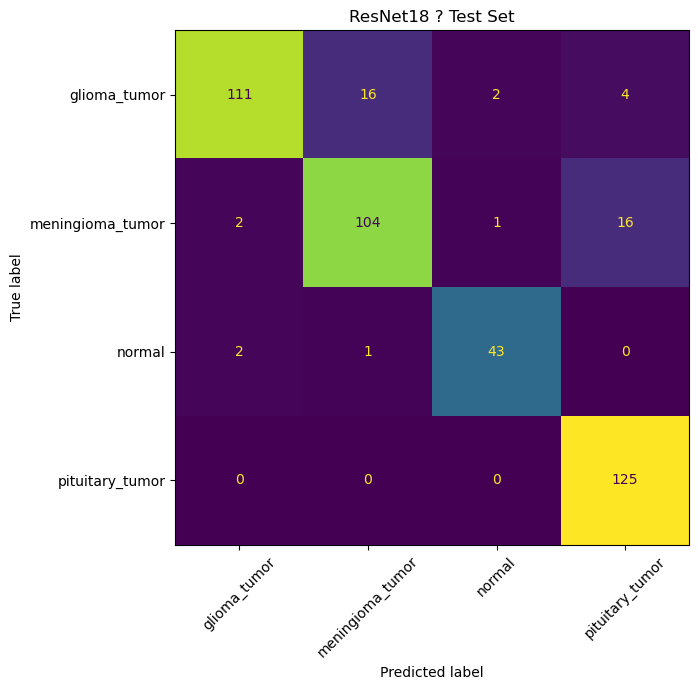

In [6]:
cm=confusion_matrix(all_labels,all_predictions,labels=list(range(len(class_names))))
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
fig,ax=plt.subplots(figsize=(8,7))
disp.plot(ax=ax,xticks_rotation=45,values_format="d",colorbar=False)
ax.set_title("ResNet18 ? Test Set")
plt.tight_layout()
plt.show()


## 7. Optional: save predictions for later comparison


## 8. Inspect misclassified images

This lists every test image whose predicted class differs from its true class and displays the images for visual inspection.


Misclassified images: 44 of 427


,filepath,true_label,predicted_label,confidence
112,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.993392
339,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.990261
232,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.987095
244,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.986203
269,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.972453
286,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.971794
399,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.967739
92,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.966239
144,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,glioma_tumor,0.963124
385,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.961515


Saved misclassified-image list to trained_models/resnet18_misclassified_images.csv


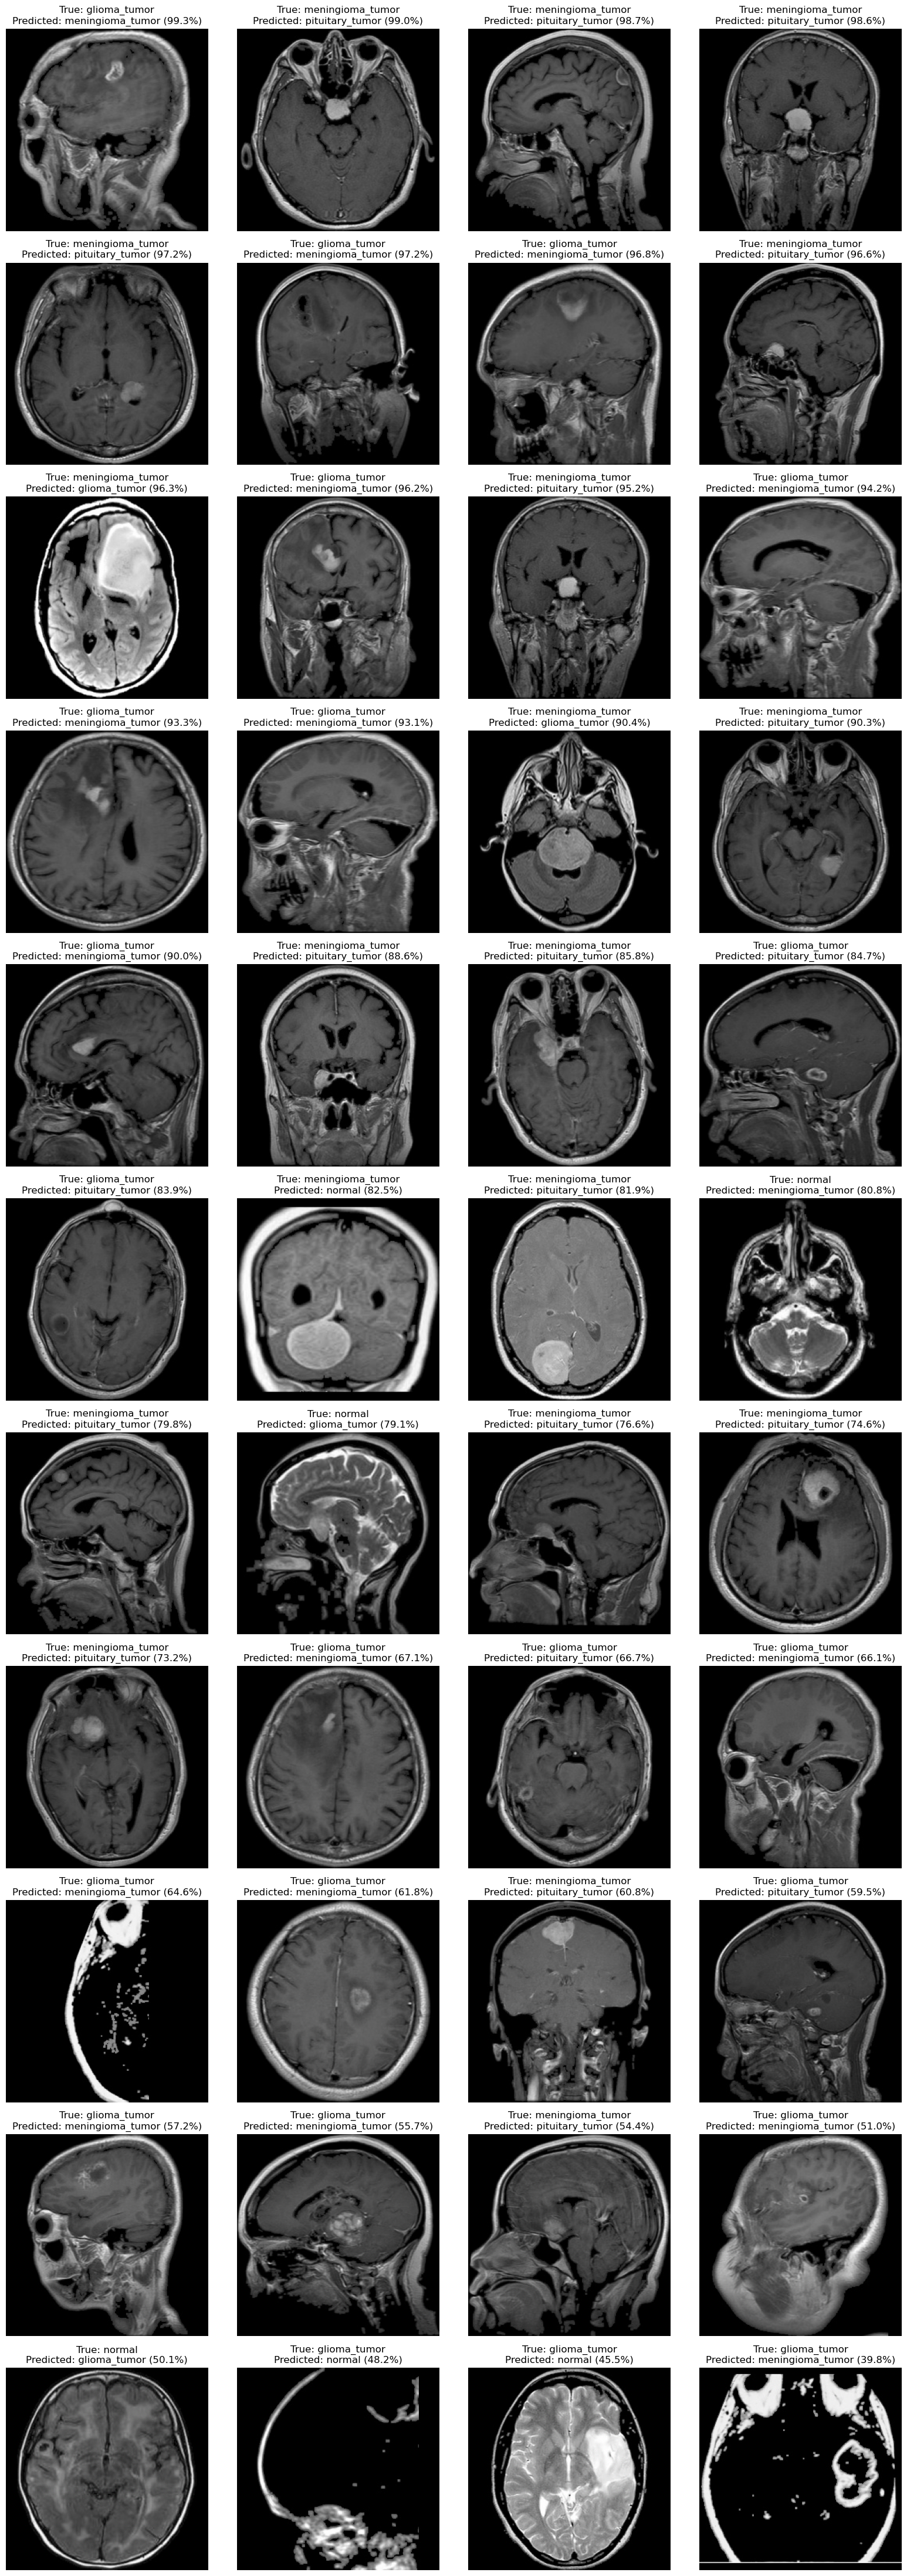

In [7]:
results_df=test_df.copy()
results_df["true_label"]=[idx_to_class[i] for i in all_labels]
results_df["predicted_label"]=[idx_to_class[i] for i in all_predictions]
results_df["confidence"]=all_confidences
misclassified_df=results_df[results_df["true_label"]!=results_df["predicted_label"]].copy()
misclassified_df=misclassified_df.sort_values("confidence",ascending=False)
print(f"Misclassified images: {len(misclassified_df)} of {len(results_df)}")
display(misclassified_df[["filepath","true_label","predicted_label","confidence"]])
misclassified_df.to_csv(Path("trained_models")/"resnet18_misclassified_images.csv",index=False)
print("Saved misclassified-image list to trained_models/resnet18_misclassified_images.csv")
columns=4
rows=(len(misclassified_df)+columns-1)//columns
if rows:
    fig,axes=plt.subplots(rows,columns,figsize=(16,4*rows))
    axes=np.atleast_1d(axes).ravel()
    for ax,(_,row) in zip(axes,misclassified_df.iterrows()):
        image=Image.open(row["filepath"])
        ax.imshow(image,cmap="gray")
        ax.set_title(f"True: {row['true_label']}\nPredicted: {row['predicted_label']} ({row['confidence']:.1%})")
        ax.axis("off")
    for ax in axes[len(misclassified_df):]: ax.axis("off")
    plt.tight_layout()
    plt.show()


In [8]:
results_df=test_df.copy()
results_df["true_label"]=[idx_to_class[i] for i in all_labels]
results_df["predicted_label"]=[idx_to_class[i] for i in all_predictions]
results_df["correct"]=results_df["true_label"]==results_df["predicted_label"]
prediction_path=Path("trained_models")/"resnet18_test_predictions.csv"
prediction_path.parent.mkdir(parents=True,exist_ok=True)
results_df.to_csv(prediction_path,index=False)
print("Saved test predictions to:",prediction_path.resolve())


Saved test predictions to: C:\Users\rickv\School\Jaar3\minor\Challenge\Brain-Tumor\brain_tumors\trained_models\resnet18_test_predictions.csv
